# Neural networks: many small models

In lecture 13 and 14 we learned about random forests which are comprised of many trees averaged together.

Today we'll learn about neural networks whic are also made of many small parts.

1. One unit of a neural net (a **node**) is kind of like a logistic regression model.
2. A neural net adds many units or "nodes" together.
3. This makes the net very **flexible**. Too flexible, for small data.
4. For small, tabular data, a neural net is not a good first choice.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.0.1 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ─────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org


## One node

Logistic regression from lecture 11 has two steps:

1. Make a linear model: $a_1 + a_2 \times x$.
2. Squash the sum into the range 0 to 1 with `inv_logit()`.

A **node** in a neural net does the same two steps:

$$ \text{node}(x) = \text{inv\_logit}(b + w \times x) $$

The intercept $b$ is called the **bias**. The slope $w$ is called the **weight**. The squash step is called the **activation function**.

Let's write the node as an R function, and look at three nodes with different weights and biases.

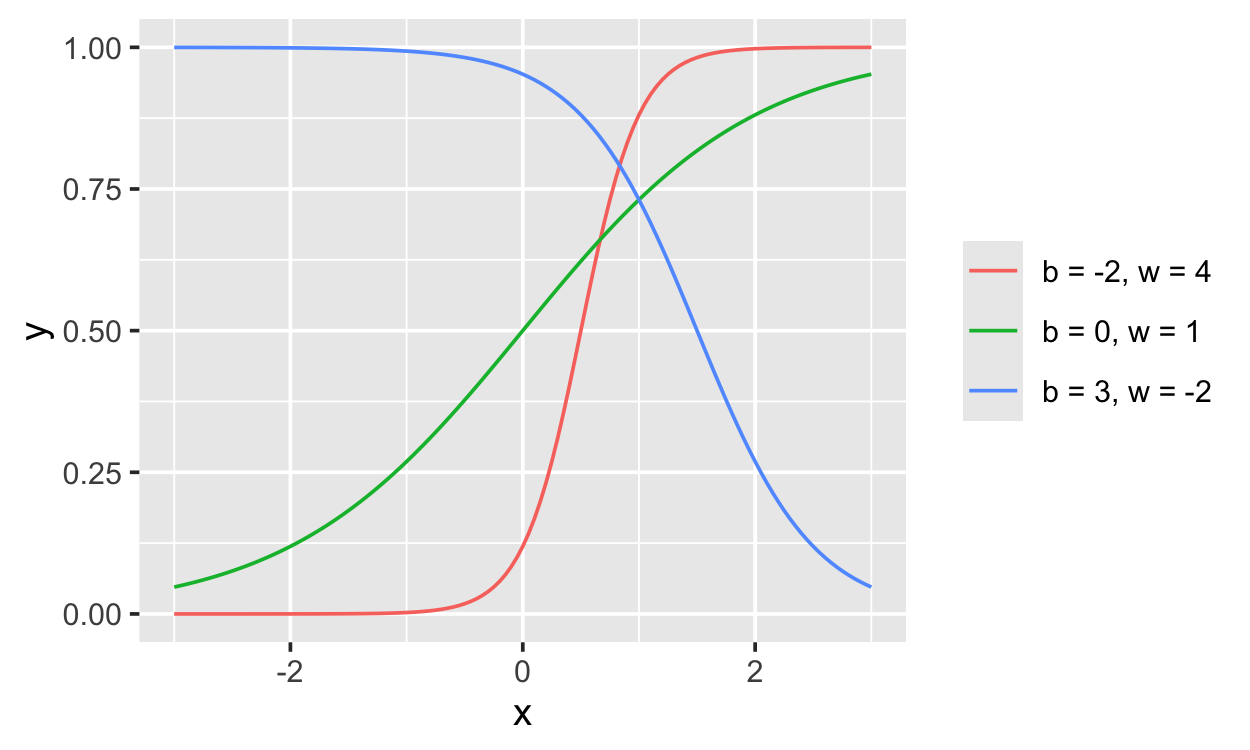

In [2]:
node <- function(x, b, w) plogis(b + w * x)   # plogis() is inv_logit()

three_nodes <- crossing(x = seq(-3, 3, by = 0.05), id = 1:3) |>
    mutate(
        b = c(0, -2, 3)[id],
        w = c(1, 4, -2)[id],
        y = node(x, b, w),
        label = paste0('b = ', b, ', w = ', w)
    )

ggplot(three_nodes, aes(x = x, y = y, color = label)) +
    geom_line() +
    labs(color = NULL)

Each node is an S-shaped curve.

- The **weight** `w` sets how steep the S is. A negative weight flips it.
- The **bias** `b` slides the S left or right.

Each node is a small, simple model.

## Many nodes make a network

A neural net has **hidden layers** and one last node adds their outputs together with more weights. The outputs of node layers become the inputs to subsequent layers.

$$ \text{prediction} = c_0 + c_1 \times \text{node}_1(x) + c_2 \times \text{node}_2(x) + c_3 \times \text{node}_3(x) $$

Each hidden node has its own `b` and `w`. The model **learns** all the numbers (`b`, `w`, and `c`) from the data.

The sum of a few S-curves can make a curve that bends many times. Let's see. Here are 60 points with a wavy pattern:

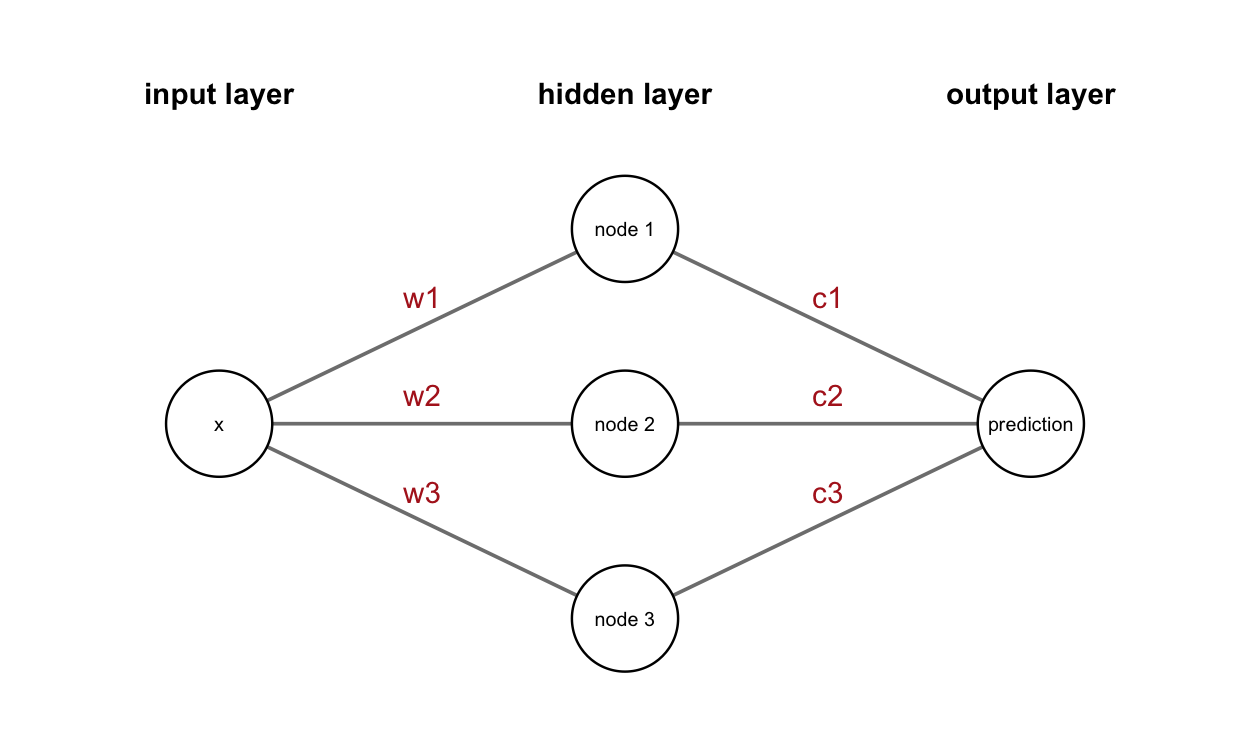

In [3]:
nodes <- tibble(
    x     = c(1, 2, 2, 2, 3),
    y     = c(0, 1, 0, -1, 0),
    label = c('x', 'node 1', 'node 2', 'node 3', 'prediction')
)

edges <- tibble(
    x    = c(1, 1, 1, 2, 2, 2),
    y    = c(0, 0, 0, 1, 0, -1),
    xend = c(2, 2, 2, 3, 3, 3),
    yend = c(1, 0, -1, 0, 0, 0),
    label = c('w1', 'w2', 'w3', 'c1', 'c2', 'c3')
) |>
    mutate(lx = (x + xend) / 2, ly = (y + yend) / 2 + 0.15)

layers <- tibble(
    x = 1:3, y = 1.7,
    label = c('input layer', 'hidden layer', 'output layer')
)

ggplot() +
    geom_segment(data = edges, aes(x = x, y = y, xend = xend, yend = yend), color = 'gray50') +
    geom_text(data = edges, aes(x = lx, y = ly, label = label), size = 3, color = 'firebrick') +
    geom_point(data = nodes, aes(x = x, y = y), size = 14, shape = 21, fill = 'white') +
    geom_text(data = nodes, aes(x = x, y = y, label = label), size = 2) +
    geom_text(data = layers, aes(x = x, y = y, label = label), fontface = 'bold', size = 3) +
    xlim(0.6, 3.4) +
    ylim(-1.5, 2) +
    theme_void()

Read the diagram from left to right. Each circle is a node..

- **Input layer:** the predictor `x`.
- **Hidden layer:** three nodes. Each one multiplies `x` by its weight (`w1`, `w2`, `w3`), adds a bias, and squashes the result with `inv_logit()`.
- **Output layer:** one node. It multiplies each hidden node by a weight (`c1`, `c2`, `c3`), and adds them up with an intercept.

This net has **one hidden layer**. Nets with many hidden layers are called "deep".

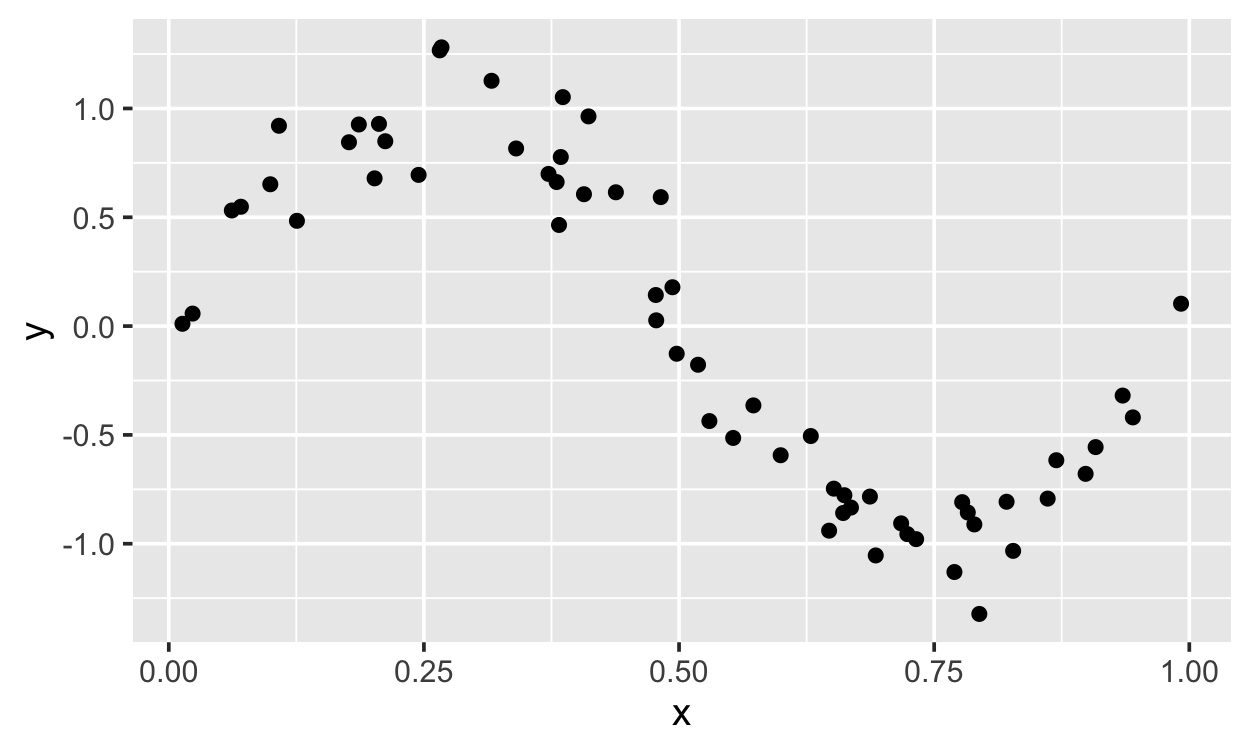

In [4]:
set.seed(1)
wavy <- tibble(x = runif(60, 0, 1)) |>
    mutate(y = sin(2 * pi * x) + rnorm(n(), sd = 0.2))

p_wavy <- ggplot(wavy, aes(x = x, y = y)) + geom_point()

p_wavy

A straight line cannot model this pattern. Let's try a neural net with **3 hidden nodes** instead.

`mlp()` fits a "multilayer perceptron", which is the simplest kind of neural net.

- `hidden_units = 3`: three nodes in the hidden layer.
- `epochs = 1000`: how many iterations to opimize the parameters.
- `penalty = 0`: no extra rule to keep the weights small. (We come back to this.)
- `set_engine('nnet')`: the R package that does the work.

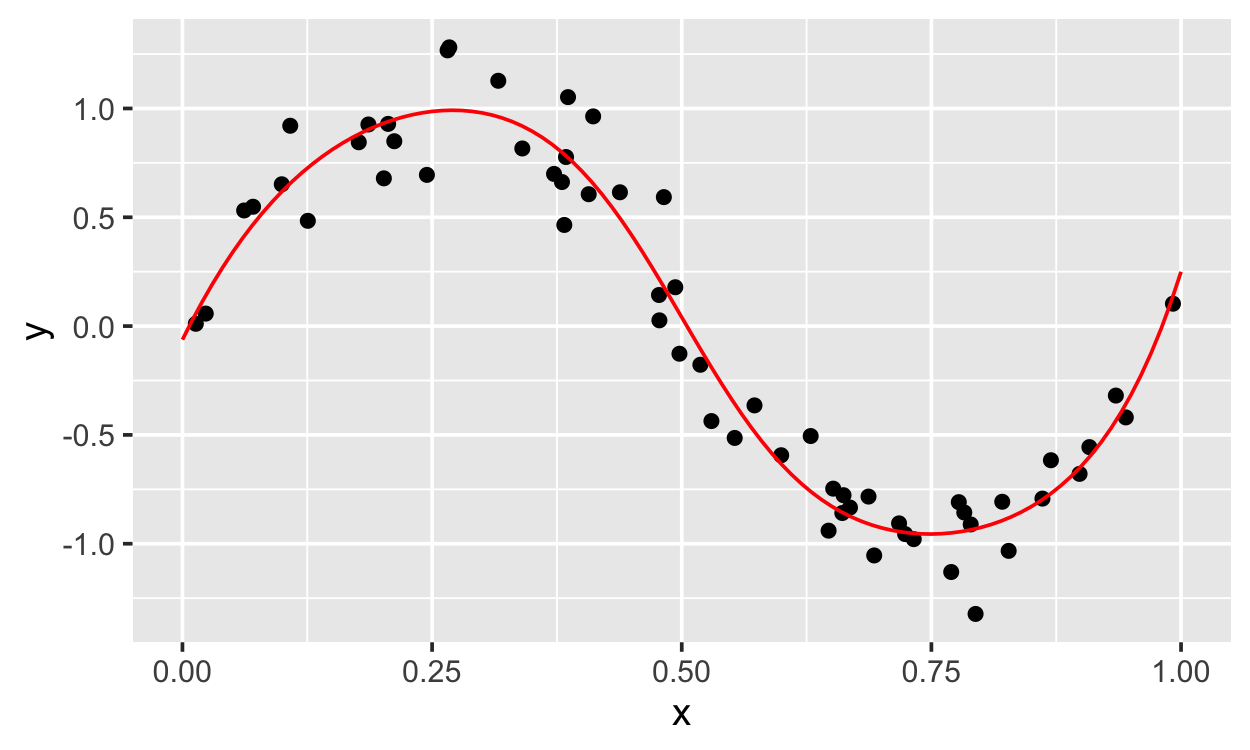

In [5]:
set.seed(1)

mod <- mlp(hidden_units = 3, epochs = 1000, penalty = 0) |>
    set_mode('regression') |>
    set_engine('nnet')

mod_fit = mod |> fit(y ~ x, data = wavy)

grid_x <- tibble(x = seq(0, 1, by = 0.01))

preds_3 <- predict(mod_fit, new_data = grid_x) |> bind_cols(grid_x)

p_wavy + geom_line(data = preds_3, aes(y = .pred), color = 'red')

Three nodes are enough to follow the wave.

## Look inside the network

Let's open the net and look at the numbers. `extract_fit_engine()` gets the `nnet` model. `coef()` gives all the weights.

In [6]:
w <- extract_fit_engine(mod_fit) |> coef()

w

     b->h1     i1->h1      b->h2     i1->h2      b->h3     i1->h3       b->o 
-14.567664  10.973361  -1.906934  -8.232652  -6.839823  13.706609   1.249933 
     h1->o      h2->o      h3->o 
 50.969536 -10.129072  -2.365810 

In [7]:
w['b->h1']

    b->h1 
-14.56766 

The names indicate what each number repressents:

- `b->h1`, `i1->h1`: the bias `b` and weight `w` of hidden node 1. Same for `h2` and `h3`.
- `b->o`: the intercept $c_0$ of the last node.
- `h1->o`, `h2->o`, `h3->o`: the weights $c_1$, $c_2$, $c_3$.

Since this is  a small network, we can do the whole prediction by hand.

Compute the three nodes. Then add them up with the `c` weights.

In [8]:
by_hand <- grid_x |>
    mutate(
        node1 = node(x, w['b->h1'], w['i1->h1']),
        node2 = node(x, w['b->h2'], w['i1->h2']),
        node3 = node(x, w['b->h3'], w['i1->h3']),
        pred  = w['b->o'] + w['h1->o'] * node1 + w['h2->o'] * node2 + w['h3->o'] * node3
    )

# is it the same as predict()?
all.equal(by_hand$pred, preds_3$.pred)

[1] TRUE

In [9]:
by_hand |> head()

  x    node1        node2      node3       pred       
1 0.00 4.713503e-07 0.12932564 0.001069148 -0.06252111
2 0.01 5.260178e-07 0.12033507 0.001226018  0.02817670
3 0.02 5.870257e-07 0.11188919 0.001405872  0.11330321
4 0.03 6.551093e-07 0.10396604 0.001612067  0.19307304
5 0.04 7.310893e-07 0.09654295 0.001848448  0.26770664
6 0.05 8.158815e-07 0.08959688 0.002119417  0.33742723

`TRUE`. The hand calculation matches `predict()`. There is no magic to a neural net. It's just nodes and sums.

In [10]:
parts <- by_hand |>
    transmute(
        x,
        `node 1` = w['h1->o'] * node1,
        `node 2` = w['h2->o'] * node2,
        `node 3` = w['h3->o'] * node3
    ) |>
    pivot_longer(-x, names_to = 'part', values_to = 'value')

parts |> head()

  x    part   value        
1 0.00 node 1  2.402450e-05
2 0.00 node 2 -1.309949e+00
3 0.00 node 3 -2.529402e-03
4 0.01 node 1  2.681088e-05
5 0.01 node 2 -1.218883e+00
6 0.01 node 3 -2.900526e-03

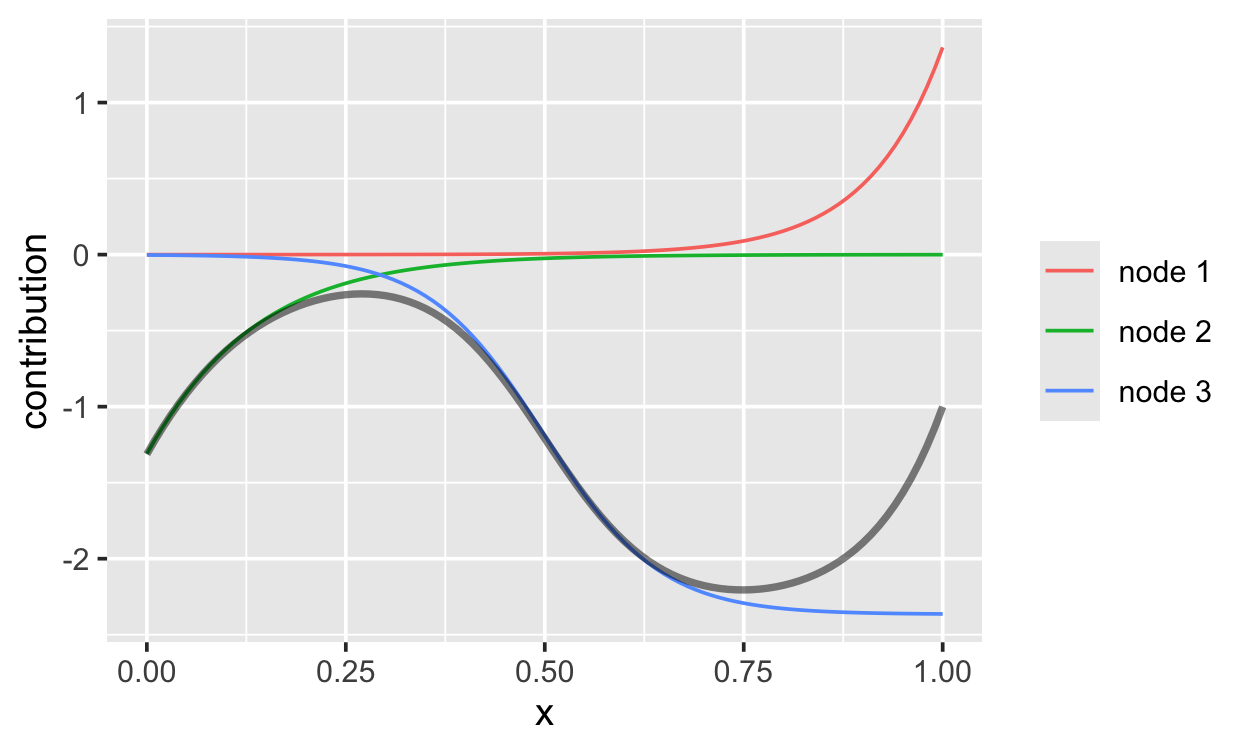

In [11]:
ggplot(parts, aes(x = x, y = value)) +
    geom_line(aes(color = part)) +
    geom_line(data = by_hand, aes(y = pred - w['b->o']), linewidth = 1, alpha = 0.5) +
    labs(color = NULL, y = 'contribution')

The colored lines are the three nodes. Each one is an S-curve that is scaled up or down and may be flipped. The thick black line is the sum of the three (the intercept `b->o` just moves the whole line up or down).

**A neural net is many small, simple models, added up.**

## More nodes, more flexible

What happens if we add more nodes? Fit nets with 1, 3, 10, and 50 hidden nodes.

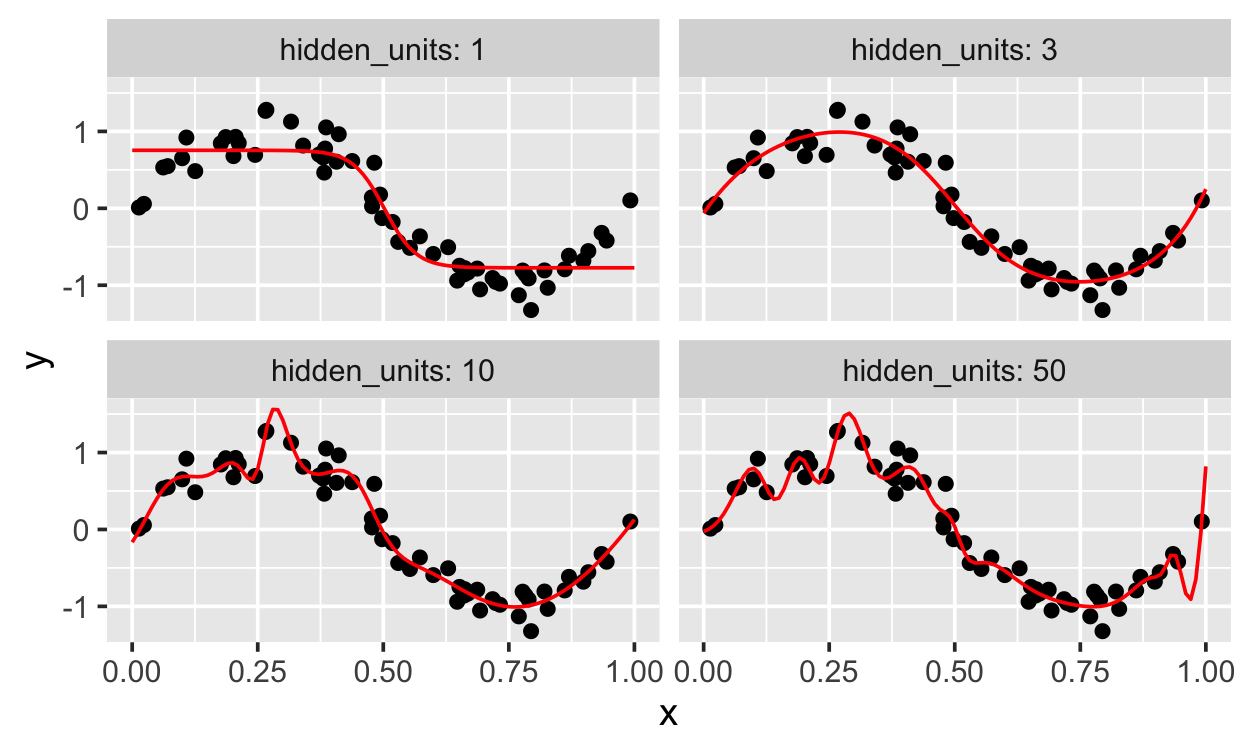

In [12]:
fit_wavy <- function(h) {
    set.seed(1)
    fit <- mlp(hidden_units = h, epochs = 1000, penalty = 0) |>
        set_mode('regression') |>
        set_engine('nnet', MaxNWts = 5000) |>
        fit(y ~ x, data = wavy)

    predict(fit, new_data = grid_x) |>
        bind_cols(grid_x) |>
        mutate(hidden_units = h)
}

preds_many <- map(c(1, 3, 10, 50), fit_wavy) |> list_rbind()

p_wavy +
    geom_line(data = preds_many, aes(y = .pred), color = 'red') +
    facet_wrap(~ hidden_units, labeller = label_both)

- 1 node: one S. It cannot follow the wave.
- 3 nodes: a good fit.
- 10 nodes and 50 nodes: the line starts to chase single points. The more nodes, the more wiggles that follow noise, not the real pattern.

How many parameters are in the 50 node net? Each node has a `b` and a `w`, plus the last node has a `c` for each node and an intercept:

$$ 50 \times 2 + 50 + 1 = 151 $$

151 numbers from 60 points! With that many numbers, the model can bend to hit almost any set of points. In theory, a neural net with enough nodes can match almost any curve. That is the good news. It is also the problem: **flexible models can memorize noise**.

## Neural nets with two predictors

Now back to the GSS and the question of lectures 11 to 13: will a person say yes to `grass`, given `educ` and `year`?

In [13]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss_grass <- gss |>
    drop_na(educ, grass) |>
    mutate(
        yes = if_else(grass == 1, 1, 0),
        grass_f = factor(grass, levels = c(2, 1), labels = c('no', 'yes'))
    )

gss_grass |> count(grass_f)

  grass_f n    
1 no      26198
2 yes     13243

### Scale the predictors

`educ` goes from 0 to 20. `year` goes from 1973 to 2024. The learning steps of a neural net work badly when predictors have such different sizes.

The fix is to **normalize**: subtract the mean and divide by the standard deviation. Then each predictor has mean 0 and standard deviation 1.

A `recipe` does this for us. A `workflow` ties the recipe and the model together, so we can still call `predict()` with the original `educ` and `year` values.

In [14]:
rec <- recipe(grass_f ~ educ + year, data = gss_grass) |>
    step_normalize(all_predictors())

fit_grass <- function(h, data = gss_grass, epochs = 500) {
    set.seed(1)
    workflow() |>
        add_recipe(rec) |>
        add_model(
            mlp(hidden_units = h, epochs = epochs, penalty = 0) |>
                set_mode('classification') |>
                set_engine('nnet', MaxNWts = 5000)
        ) |>
        fit(data = data)
}

Reuse the `plot_boundary()` function and the `grid` from lecture 13.

In [15]:
grid <- crossing(educ = 0:20, year = 1973:2024)

plot_boundary <- function(fit, grid) {
    preds <- fit |>
        predict(new_data = grid, type = 'prob') |>
        bind_cols(grid)

    ggplot(preds, aes(x = year, y = educ)) +
        geom_tile(aes(fill = .pred_yes)) +
        geom_contour(aes(z = .pred_yes), breaks = 0.5, color = 'black') +
        scale_fill_gradient2(low = 'steelblue', mid = 'white', high = 'darkorange',
                             midpoint = 0.5, limits = c(0, 1))
}

### One hidden node

First, only one hidden node.

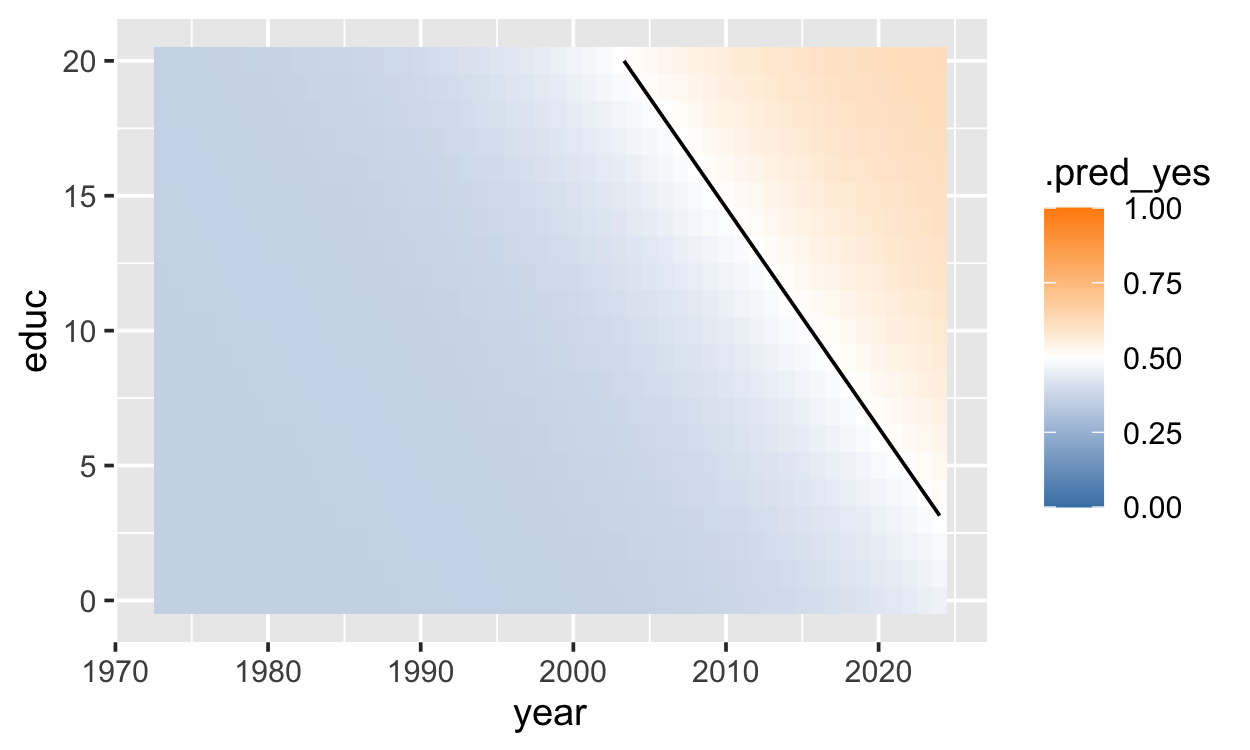

In [16]:
nn_1 <- fit_grass(1)

plot_boundary(nn_1, grid)

A straight line, just like logistic regression! This makes sense. One node is one logistic regression: a weighted sum, then an S. The last node can only stretch or flip the S. So the 0.5 line is still a straight line.

### More hidden nodes

Try 3 nodes and 30 nodes.

In [17]:
nn_3 <- fit_grass(3)
nn_30 <- fit_grass(30)

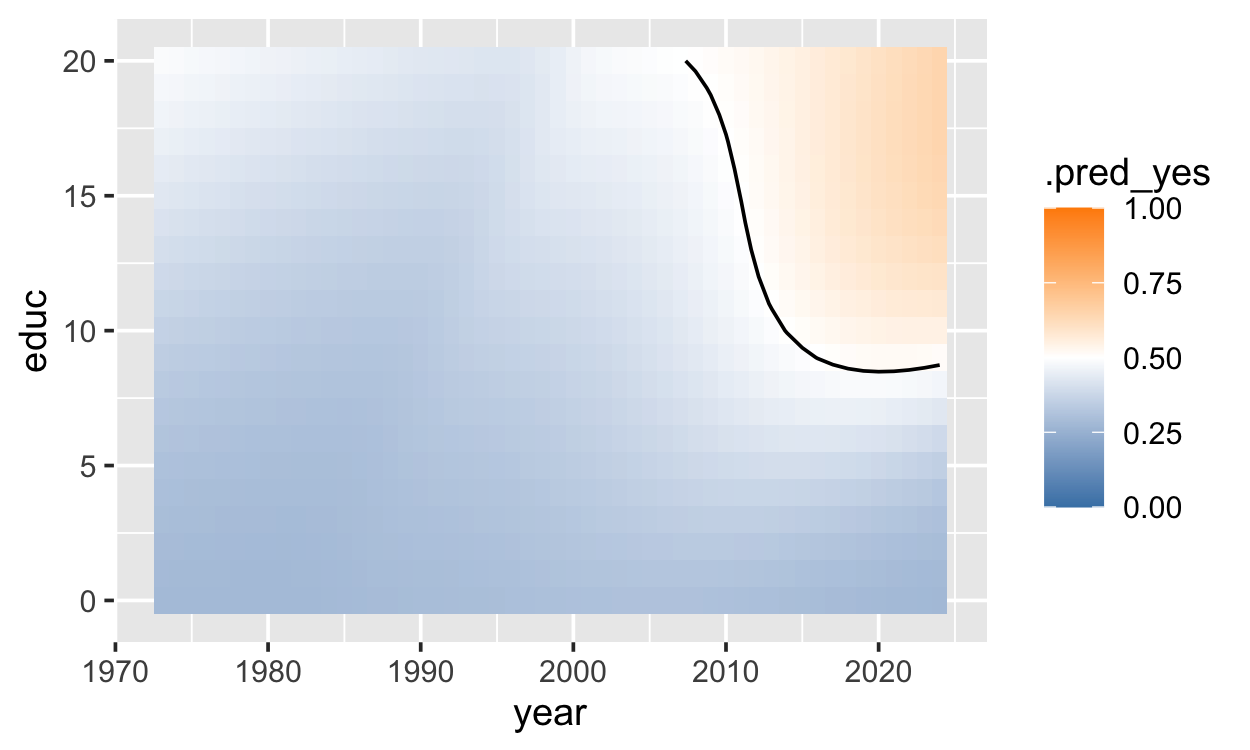

In [18]:
plot_boundary(nn_3, grid)

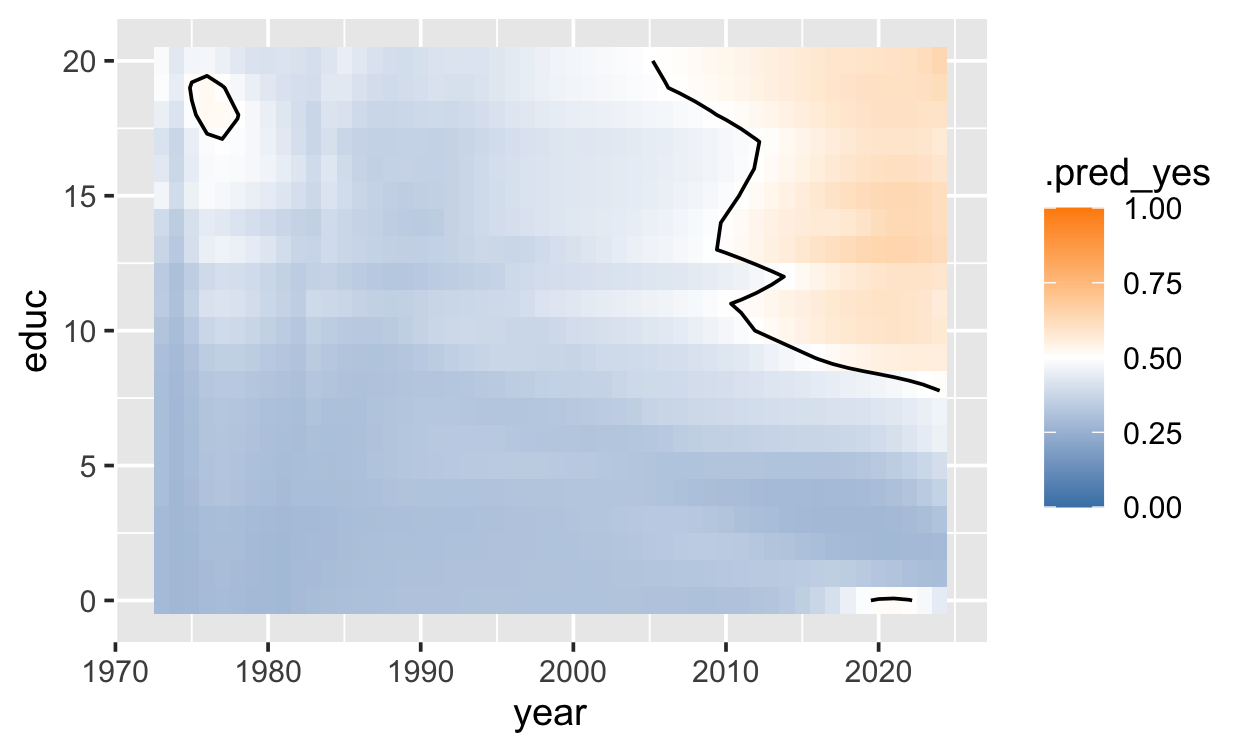

In [19]:
plot_boundary(nn_30, grid)

With 3 nodes, the boundary can bend. With 30 nodes, the boundary can bend a lot more.

## Does the flexibility help?

Let's actually test our model properly. We need to split our data into training and test data:
- **training** set: the model learns from these people.
- **testing** set: the model has never seen these people. We measure accuracy here.

`initial_split()` makes the split. `training()` and `testing()` get each part.

In [20]:
set.seed(512)

split <- initial_split(gss_grass, prop = 0.5, strata = grass_f)
train <- training(split)
test  <- testing(split)

nrow(train)

[1] 19720

In [21]:
nrow(test)

[1] 19721

We have a lot of training data (many thousands of people). Real projects often have fewer training examples. To see the how data size impacts out models let's also make a big and small training set:

- **big**: all the training data.
- **small**: only 100 randomly chosen people from the training data.

For each training set, 
1. fit a logistic regression,
2. a random forest,
3. and neural nets with 2, 10, and 50 hidden nodes.


Measure the accuracy on the training set and on the testing set.

In [22]:
accuracy_of <- function(fit, data) {
    pred <- predict(fit, new_data = data, type = 'class')$.pred_class
    mean(pred == data$grass_f)
}

compare_models <- function(train_data) {
    fits <- list(
        logistic    = workflow() |> add_recipe(rec) |> add_model(logistic_reg()) |> fit(data = train_data),
        forest      = rand_forest(trees = 200) |> set_mode('classification') |> set_engine('ranger') |>
                          fit(grass_f ~ educ + year, data = train_data),
        `nn 2`      = fit_grass(2, train_data, epochs = 1000),
        `nn 10`     = fit_grass(10, train_data, epochs = 1000),
        `nn 50`     = fit_grass(50, train_data, epochs = 1000)
    )

    tibble(
        model = names(fits),
        train_accuracy = map_dbl(fits, accuracy_of, data = train_data),
        test_accuracy  = map_dbl(fits, accuracy_of, data = test)
    )
}

set.seed(3)
train_small <- train |> slice_sample(n = 100)

results <- bind_rows(
    compare_models(train)       |> mutate(training_size = 'big'),
    compare_models(train_small) |> mutate(training_size = 'small (n = 100)')
)

results

   model    train_accuracy test_accuracy training_size  
1  logistic 0.7082657      0.7091932     big            
2  forest   0.7157201      0.7130977     big            
3  nn 2     0.7106491      0.7126413     big            
4  nn 10    0.7129310      0.7145175     big            
5  nn 50    0.7141481      0.7099539     big            
6  logistic 0.7100000      0.6833325     small (n = 100)
7  forest   0.8100000      0.6791238     small (n = 100)
8  nn 2     0.7900000      0.6766391     small (n = 100)
9  nn 10    0.9000000      0.6208610     small (n = 100)
10 nn 50    0.9100000      0.6226358     small (n = 100)

Look at `training_size = 'small (n = 100)'` first.

- Training accuracy **goes up** with more nodes.
- Testing accuracy **goes down** with more nodes. On unseen people, the 50 node net is much worse.

The forest also fits the 100 people too well (81% on training, much less on testing). The big net has memorized the 100 exampes in the small training set. This is **overfitting**.

Now look at the big training set. Logistic regression is just as good as a neural net.

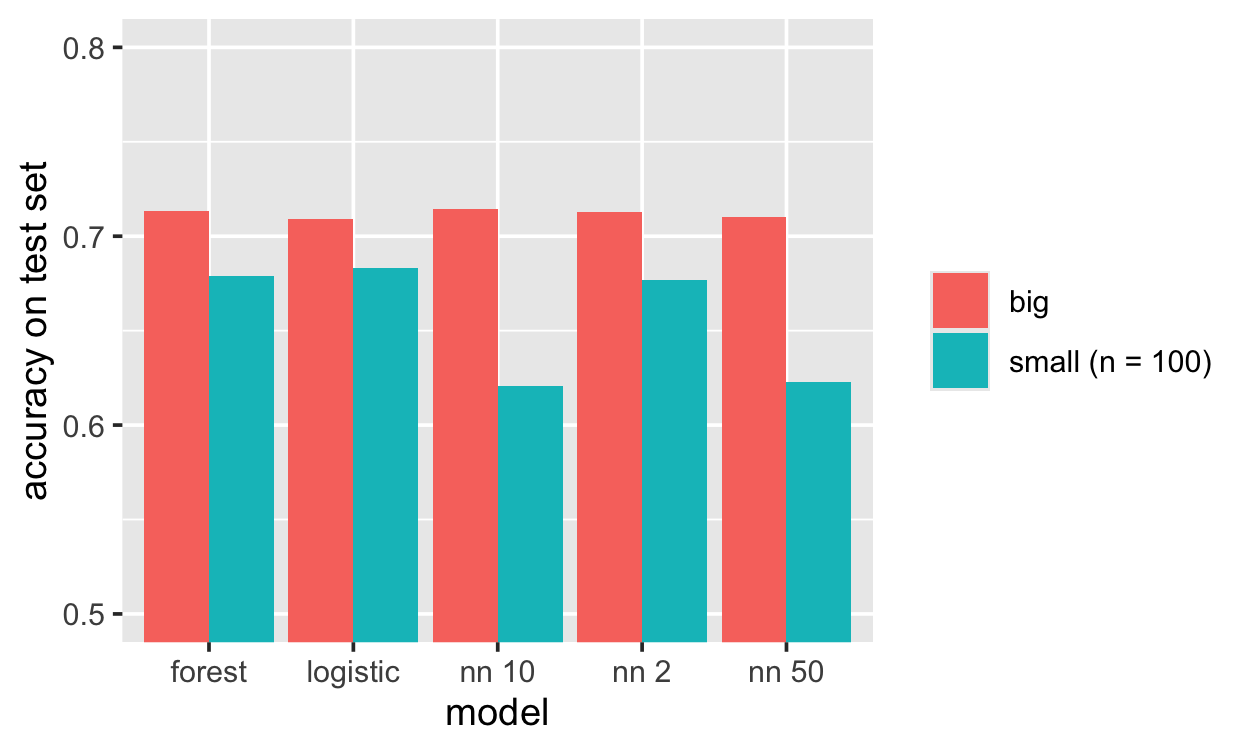

In [23]:
ggplot(results, aes(x = model, y = test_accuracy, fill = training_size)) +
    geom_col(position = 'dodge') +
    coord_cartesian(ylim = c(0.5, 0.8)) +
    labs(fill = NULL, y = 'accuracy on test set')

## Why neural nets are not the first choice for small, tabular data

**Tabular data** is a table: rows are people (or days, or countries) and columns are named variables like `educ` and `year`. Most data in biostatistics is tabular.

For tabular data:

- **Many numbers to learn, few rows.** A net with 50 nodes had 201 numbers to learn from 100 rows. The data cannot pin down so many numbers. It overfits.
- **They need more care.** We had to normalize the predictors, pick the number of nodes, and pick the number of `epochs`. A forest needed none of this.
- **No simple win.** On tabular data, a forest or a plain regression is often just as good as a neural net. And it is faster to fit and to explain.

Neural nets are great for data where there are very many rows and the "predictors" are raw things like pixels or sound: images, speech, and text.